# Deep Learning: 2st Assignment

# Libraries

In [2]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
print("GPU available:    ", torch.cuda.is_available())

GPU available:     True


# Task 1: Getting the CIFAR Dataset
 NUM_WORKERS – number of background processes that load and augment images while the GPU is training, so the CPU-side augmentation runs in parallel and never makes the GPU wait.

MP_CONTEXT is set to fork because of how linux works with custom transforms

In [3]:
import os
DATA_PATH = "./dataset"
NUM_WORKERS = min(8, os.cpu_count())
MP_CONTEXT = "fork" if NUM_WORKERS > 0 else None
IMG_SIZE = 224
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

In [36]:
raw_train = datasets.CIFAR10(root=DATA_PATH, train=True, download=True)
raw_test = datasets.CIFAR10(root=DATA_PATH, train=False, download=True)

print("Dataset loaded successfully")
print("Training images:", len(raw_train))
print("Test images:    ", len(raw_test))
print("Array shape (N, H, W, C):", raw_train.data.shape)
CLASSES = raw_train.classes
print("Classes:", CLASSES)

image, label = raw_train[0]
print("First item:", "label =", label, "is a", CLASSES[label])

Dataset loaded successfully
Training images: 50000
Test images:     10000
Array shape (N, H, W, C): (50000, 32, 32, 3)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
First item: label = 6 is a frog


# Task 2: Defining the Network

## custom CNN

In [6]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),    
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),   
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                   

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),   
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),   
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                   

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),  
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                   
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                    
            nn.Linear(128 * 4 * 4, 256),     
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(256, num_classes),     
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

## Pretrained CNN

In [18]:
PRETRAINED = {
    
    "resnet50":       (models.resnet50,       models.ResNet50_Weights.IMAGENET1K_V2),       
    "densenet121":    (models.densenet121,    models.DenseNet121_Weights.IMAGENET1K_V1),    
    "convnext_tiny":  (models.convnext_tiny,  models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),  
    "convnext_base":  (models.convnext_base,  models.ConvNeXt_Base_Weights.IMAGENET1K_V1),  
}


def build_pretrained(arch="convnext_base", freeze_backbone=False, num_classes=10):
    builder, weights = PRETRAINED[arch]
    if arch.startswith("convnext"):
        net = builder(weights=weights, stochastic_depth_prob=0.2)
    else:
        net = builder(weights=weights)

    if freeze_backbone:                       
        for param in net.parameters():        
            param.requires_grad = False

    if arch.startswith("resnet"):
        net.fc = nn.Linear(net.fc.in_features, num_classes)                          
    elif arch.startswith("densenet"):
        net.classifier = nn.Linear(net.classifier.in_features, num_classes)          
    else:
        net.classifier[2] = nn.Linear(net.classifier[2].in_features, num_classes)    

    return nn.Sequential(
        nn.Upsample(size=IMG_SIZE, mode="bilinear", align_corners=False),   
        net,
    )

## Training and testing functions

In [19]:
def train(model, loader, optimizer, criterion, scaler, scheduler):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, 100.0 * correct / total

## Test function

In [20]:
def test(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16):
                outputs = model(images)
            loss = F.cross_entropy(outputs.float(), labels)

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, 100.0 * correct / total

# Task 3: Loading Data

In [37]:
plain_set = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=transforms.ToTensor())
plain_loader = DataLoader(plain_set, batch_size=64, shuffle=True,
                          num_workers=NUM_WORKERS, multiprocessing_context=MP_CONTEXT)

images, labels = next(iter(plain_loader))
print("Images tensor size:", images.shape, " (batch, channels, height, width)")
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([64, 3, 32, 32])  (batch, channels, height, width)
Labels tensor size: torch.Size([64])


In [22]:
MEAN = (0.485, 0.456, 0.406)    
STD = (0.229, 0.224, 0.225)
def show_images(images, labels, title=None, n=8, normalized=False):
    images = images[:n]
    if normalized:                                     
        images = images * torch.tensor(STD).view(1, 3, 1, 1) + torch.tensor(MEAN).view(1, 3, 1, 1)
    images = images.clamp(0, 1)

    plt.figure(figsize=(8, 8))
    for i in range(n):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].permute(1, 2, 0).numpy())   # C x H x W -> H x W x C
        plt.title(CLASSES[labels[i]], fontsize=9)
        plt.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()

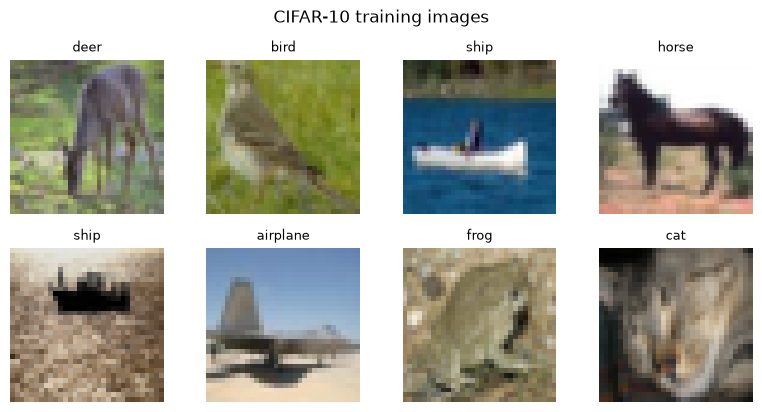

In [15]:
show_images(images, labels, title="CIFAR-10 training images")

# Task 4: Dataset Augmentation

In [16]:
class AddGaussianNoise:
    def __init__(self, std=0.05):
        self.std = std

    def __call__(self, tensor):
        noisy = tensor + torch.randn_like(tensor) * self.std   # randn_like: normal noise with the same shape
        return noisy.clamp(0, 1)                               # keep pixel values inside [0, 1]


class AddSaltPepperNoise:
    def __init__(self, amount=0.02):
        self.amount = amount

    def __call__(self, tensor):
        tensor = tensor.clone()
        mask = torch.rand(tensor.shape[1:])                    # one random number per pixel (H x W)
        tensor[:, mask < self.amount / 2] = 0.0                # pepper: black pixels
        tensor[:, mask > 1 - self.amount / 2] = 1.0            # salt: white pixels
        return tensor

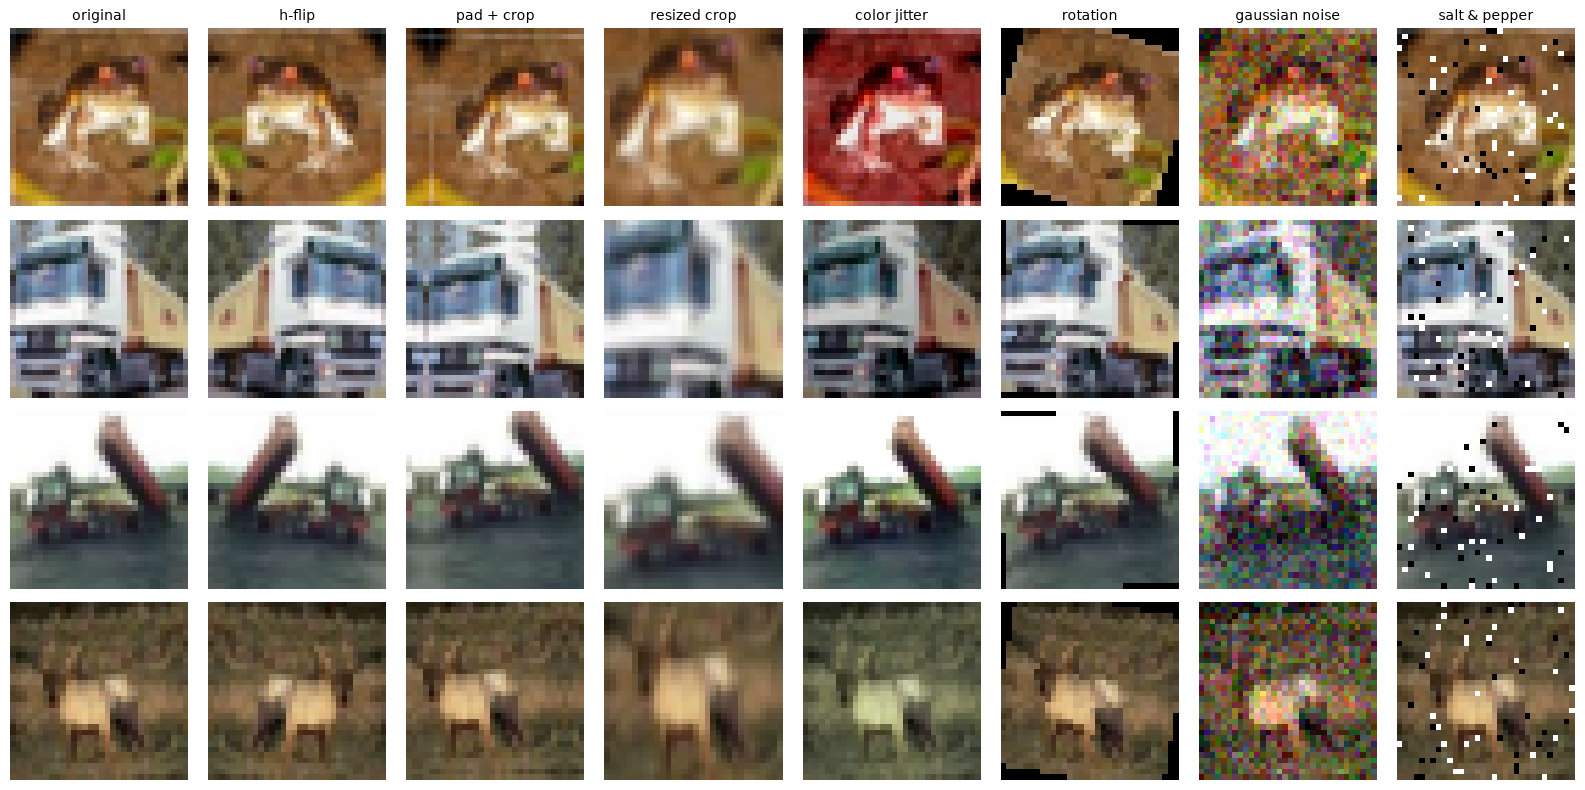

In [17]:
single_transforms = {
    "original":       transforms.ToTensor(),
    "h-flip":         transforms.Compose([transforms.RandomHorizontalFlip(p=1.0), transforms.ToTensor()]),
    "pad + crop":     transforms.Compose([transforms.RandomCrop(32, padding=4, padding_mode="reflect"), transforms.ToTensor()]),
    "resized crop":   transforms.Compose([transforms.RandomResizedCrop(32, scale=(0.5, 0.8)), transforms.ToTensor()]),
    "color jitter":   transforms.Compose([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1), transforms.ToTensor()]),
    "rotation":       transforms.Compose([transforms.RandomRotation(25), transforms.ToTensor()]),
    "gaussian noise": transforms.Compose([transforms.ToTensor(), AddGaussianNoise(0.1)]),
    "salt & pepper":  transforms.Compose([transforms.ToTensor(), AddSaltPepperNoise(0.05)]),
}

to_pil = transforms.ToPILImage()
plt.figure(figsize=(16, 8))
for row in range(4):
    pil_image = to_pil(raw_train.data[row])          # NumPy array (H x W x C) -> PIL image
    for col, (name, tf) in enumerate(single_transforms.items()):
        plt.subplot(4, len(single_transforms), row * len(single_transforms) + col + 1)
        plt.imshow(tf(pil_image).permute(1, 2, 0).numpy())
        plt.axis("off")
        if row == 0:
            plt.title(name, fontsize=10)
plt.tight_layout()
plt.show()

train_transform batch: torch.Size([16, 3, 32, 32])


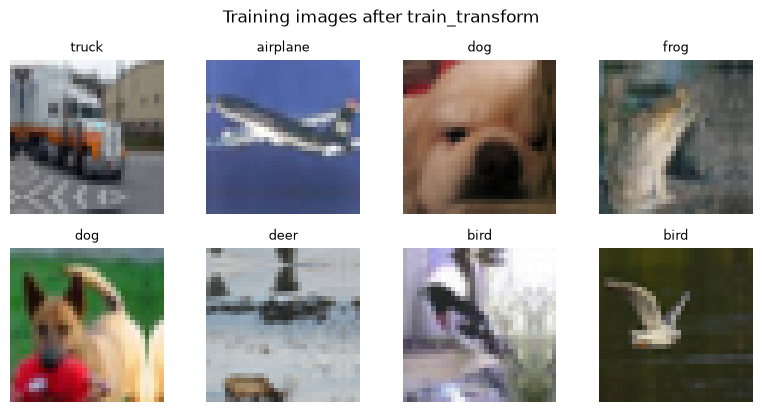

heavy_transform batch: torch.Size([16, 3, 32, 32])


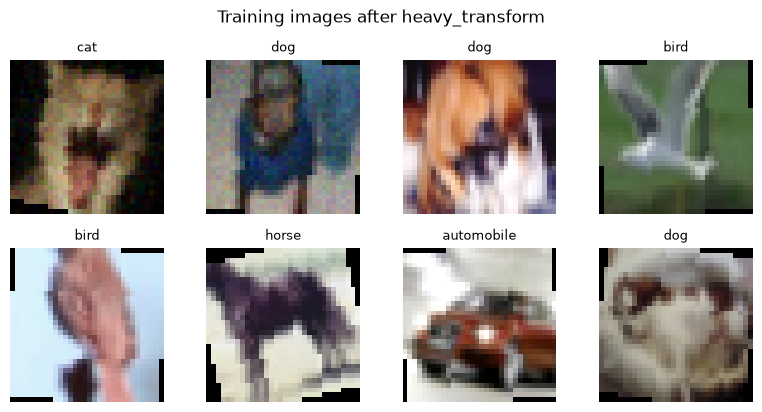

In [23]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

heavy_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.RandomApply([AddGaussianNoise(0.03)], p=0.3),     # RandomApply: use the noise 30 % of the time
    transforms.RandomApply([AddSaltPepperNoise(0.02)], p=0.2),
    transforms.Normalize(MEAN, STD),
])

for name, tf in [("train_transform", train_transform), ("heavy_transform", heavy_transform)]:
    augmented_set = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=tf)
    aug_images, aug_labels = next(iter(DataLoader(augmented_set, batch_size=16, shuffle=True)))
    print(name, "batch:", aug_images.shape)
    show_images(aug_images, aug_labels, title="Training images after " + name, normalized=True)

## training / validation / testing split

In [24]:
perm = np.random.default_rng(SEED).permutation(len(raw_train))
train_idx, val_idx = perm[5000:], perm[:5000]
print("train / validation / test images:", len(train_idx), len(val_idx), len(raw_test))


def make_loaders(train_tf, batch_size, final=False):
    train_full = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=train_tf)
    if final:
        train_ds = train_full
        eval_ds = datasets.CIFAR10(root=DATA_PATH, train=False, download=False, transform=test_transform)
    else:
        train_ds = Subset(train_full, train_idx)
        eval_full = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=test_transform)
        eval_ds = Subset(eval_full, val_idx)

    loader_args = dict(num_workers=NUM_WORKERS, multiprocessing_context=MP_CONTEXT,
                       pin_memory=True, persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True, **loader_args)
    eval_loader = DataLoader(eval_ds, batch_size=256, shuffle=False, **loader_args)
    return train_loader, eval_loader

train / validation / test images: 45000 5000 10000


# Task 5: Training Function and Tuning hyperparameters

## mixed precision is used to accelerate the computation speed

In [26]:
def fit(model, train_loader, eval_loader, epochs, lr, weight_decay=0.05, label_smoothing=0.1):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, pct_start=0.2,
                                                    total_steps=epochs * len(train_loader))
    scaler = torch.amp.GradScaler()

    history = {"train_loss": [], "train_acc": [], "eval_loss": [], "eval_acc": [], "epoch_time": []}
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = train(model, train_loader, optimizer, criterion, scaler, scheduler)
        eval_loss, eval_acc = test(model, eval_loader)
        elapsed = time.time() - start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["eval_loss"].append(eval_loss)
        history["eval_acc"].append(eval_acc)
        history["epoch_time"].append(elapsed)
        print("Epoch {:2d}/{} | train loss {:.4f} acc {:6.2f}% | eval loss {:.4f} acc {:6.2f}% | {:.0f}s".format(
            epoch, epochs, train_loss, train_acc, eval_loss, eval_acc, elapsed))
    return model, history

In [27]:
def plot_history(history, eval_name, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.plot(epochs, history["train_loss"], marker="o")
    plt.title("Training loss"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.grid(alpha=0.3)

    plt.subplot(1, 3, 2)
    plt.plot(epochs, history["train_loss"], marker="o", label="train loss (label smoothing)")
    plt.plot(epochs, history["eval_loss"], marker="o", label=eval_name + " loss")
    plt.title("Train vs {} loss".format(eval_name)); plt.xlabel("epoch"); plt.ylabel("loss")
    plt.legend(); plt.grid(alpha=0.3)

    plt.subplot(1, 3, 3)
    plt.plot(epochs, history["eval_acc"], marker="o", color="green")
    plt.title(eval_name.capitalize() + " accuracy"); plt.xlabel("epoch"); plt.ylabel("accuracy (%)")
    plt.grid(alpha=0.3)

    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [30]:
SCRATCH_NOAUG_EPOCHS = 15
SCRATCH_AUG_EPOCHS = 60
TRANSFER_EPOCHS = 6
BATCH_SIZE = 64

def make_model(kind, arch="convnext_base"):
    if kind == "scratch":
        return CustomCNN()
    return build_pretrained(arch, freeze_backbone=(kind == "frozen"))


experiments = [
    # name                                           model       architecture      augmentation     lr    epochs
    ("1. CustomCNN, no augmentation",                "scratch",  None,             test_transform,  1e-3, SCRATCH_NOAUG_EPOCHS),
    ("2. CustomCNN, augmentation",                   "scratch",  None,             train_transform, 1e-3, SCRATCH_AUG_EPOCHS),
    ("3. ResNet-50 fine-tune, lr 1e-4",              "finetune", "resnet50",       train_transform, 1e-4, TRANSFER_EPOCHS),
    ("4. DenseNet-121 fine-tune, lr 1e-4",           "finetune", "densenet121",    train_transform, 1e-4, TRANSFER_EPOCHS),
    ("5. ConvNeXt-Tiny fine-tune, lr 1e-4",          "finetune", "convnext_tiny",  train_transform, 1e-4, TRANSFER_EPOCHS),
    ("6. ConvNeXt-Base fine-tune, lr 1e-4",          "finetune", "convnext_base",  train_transform, 1e-4, TRANSFER_EPOCHS),
    ("7. ConvNeXt-Base frozen backbone, lr 1e-3",    "frozen",   "convnext_base",  train_transform, 1e-3, TRANSFER_EPOCHS),
    ("8. ConvNeXt-Base fine-tune, lr 3e-4",          "finetune", "convnext_base",  train_transform, 3e-4, TRANSFER_EPOCHS),
    ("9. ConvNeXt-Base fine-tune, lr 1e-4, heavy aug", "finetune", "convnext_base", heavy_transform, 1e-4, TRANSFER_EPOCHS),
]

histories = {}
for name, kind, arch, train_tf, lr, epochs in experiments:
    print("=" * 95)
    print(name)
    set_seed()
    train_loader, val_loader = make_loaders(train_tf, BATCH_SIZE)
    model, history = fit(make_model(kind, arch), train_loader, val_loader, epochs, lr)
    histories[name] = history
    del model, train_loader, val_loader     # free GPU memory and worker processes before the next experiment
    torch.cuda.empty_cache()

print()
print("{:<50} {:>11} {:>10} {:>9} {:>10}".format("experiment", "train loss", "val loss", "val acc", "s/epoch"))
for name, h in histories.items():
    print("{:<50} {:>11.4f} {:>10.4f} {:>8.2f}% {:>10.0f}".format(
        name, h["train_loss"][-1], h["eval_loss"][-1], h["eval_acc"][-1], np.mean(h["epoch_time"])))

1. CustomCNN, no augmentation
Epoch  1/15 | train loss 1.9925 acc  29.56% | eval loss 1.5495 acc  43.88% | 4s
Epoch  2/15 | train loss 1.6296 acc  48.14% | eval loss 1.2579 acc  57.10% | 3s
Epoch  3/15 | train loss 1.3944 acc  60.99% | eval loss 1.0188 acc  65.30% | 3s
Epoch  4/15 | train loss 1.2263 acc  69.70% | eval loss 0.8917 acc  70.60% | 3s
Epoch  5/15 | train loss 1.1213 acc  74.67% | eval loss 0.7731 acc  75.60% | 3s
Epoch  6/15 | train loss 1.0389 acc  78.90% | eval loss 0.6990 acc  77.42% | 3s
Epoch  7/15 | train loss 0.9662 acc  82.63% | eval loss 0.6904 acc  78.72% | 3s
Epoch  8/15 | train loss 0.9007 acc  85.78% | eval loss 0.6642 acc  78.60% | 3s
Epoch  9/15 | train loss 0.8417 acc  88.91% | eval loss 0.6481 acc  80.34% | 3s
Epoch 10/15 | train loss 0.7852 acc  91.87% | eval loss 0.6281 acc  80.84% | 3s
Epoch 11/15 | train loss 0.7416 acc  94.07% | eval loss 0.6187 acc  81.28% | 3s
Epoch 12/15 | train loss 0.7078 acc  95.91% | eval loss 0.6160 acc  81.16% | 3s
Epoch 13/1

## further training for the best model

In [33]:
FINAL = {
    "model": "finetune",             
    "arch": "convnext_base",
    "augmentation": train_transform,
    "learning_rate": 1e-4,            
    "batch_size": 64,
    "epochs": 10,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
}

set_seed()
train_loader, test_loader = make_loaders(FINAL["augmentation"], FINAL["batch_size"], final=True)
final_model, final_history = fit(make_model(FINAL["model"], FINAL["arch"]), train_loader, test_loader,
                                 FINAL["epochs"], FINAL["learning_rate"],
                                 weight_decay=FINAL["weight_decay"], label_smoothing=FINAL["label_smoothing"])

Epoch  1/10 | train loss 1.0728 acc  81.25% | eval loss 0.1735 acc  96.93% | 377s
Epoch  2/10 | train loss 0.5777 acc  96.84% | eval loss 0.1740 acc  96.65% | 376s
Epoch  3/10 | train loss 0.5456 acc  98.18% | eval loss 0.1763 acc  96.97% | 375s
Epoch  4/10 | train loss 0.5308 acc  98.75% | eval loss 0.1559 acc  97.53% | 375s
Epoch  5/10 | train loss 0.5201 acc  99.21% | eval loss 0.1464 acc  97.86% | 375s
Epoch  6/10 | train loss 0.5119 acc  99.53% | eval loss 0.1405 acc  98.16% | 375s
Epoch  7/10 | train loss 0.5072 acc  99.74% | eval loss 0.1385 acc  98.31% | 375s
Epoch  8/10 | train loss 0.5040 acc  99.86% | eval loss 0.1358 acc  98.45% | 375s
Epoch  9/10 | train loss 0.5027 acc  99.93% | eval loss 0.1313 acc  98.64% | 375s
Epoch 10/10 | train loss 0.5016 acc  99.97% | eval loss 0.1311 acc  98.65% | 375s


## Plotting the model performance

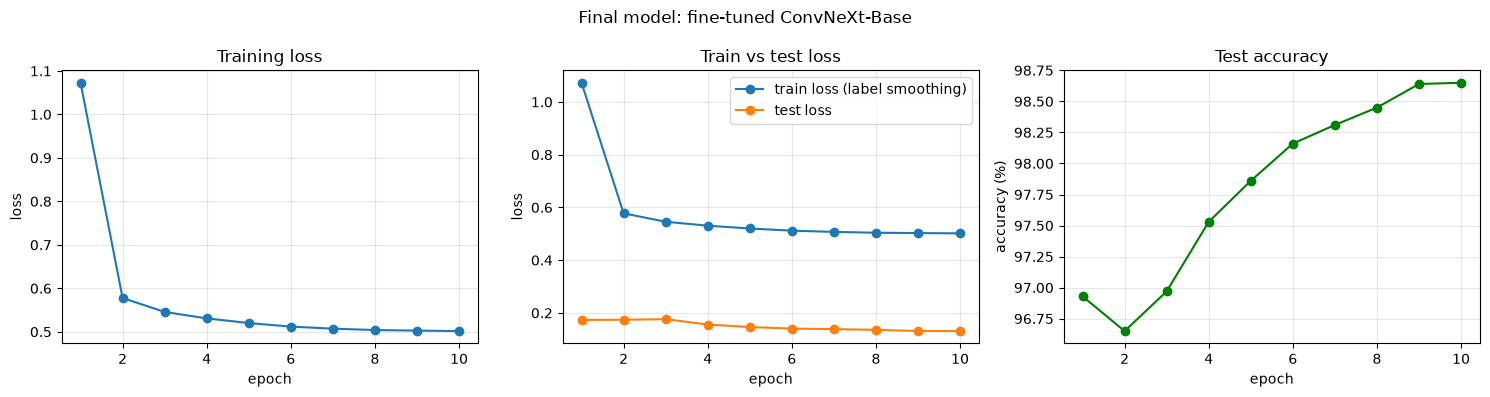

Final train loss (augmented, label smoothing): 0.5016
Final train loss (clean images):               0.0871   train accuracy 99.99%
Final test loss:                               0.1311
Final test accuracy:                           98.65%


In [34]:
plot_history(final_history, eval_name="test", title="Final model: fine-tuned ConvNeXt-Base")

clean_train_loader, _ = make_loaders(test_transform, 256, final=True)
clean_train_loss, clean_train_acc = test(final_model, clean_train_loader)
test_loss, test_acc = test(final_model, test_loader)

print("Final train loss (augmented, label smoothing): {:.4f}".format(final_history["train_loss"][-1]))
print("Final train loss (clean images):               {:.4f}   train accuracy {:.2f}%".format(clean_train_loss, clean_train_acc))
print("Final test loss:                               {:.4f}".format(test_loss))
print("Final test accuracy:                           {:.2f}%".format(test_acc))

# Results summary, architecture/design

Best network design: transfer learning using ConvNeXt-Base which is pretrained on ImageNet. last layer (the fully connected layer) replaced by Linear(1024, 10) (10 classes), all layers fine-tuned (unfrozen). Images upsampled from 32×32 to 224×224 (because of the ImageNet), ImageNet normalisation, optimizer: AdamW (peak lr 0.0001, OneCycle schedule, weight decay 0.05), label smoothing 0.1 for the cross entropy loss, stochastic depth 0.2, batch size 64, mixed precision (used for faster computation) (float16), 10 epochs on all 50,000 training images.

Train loss: 0.5016
Train accuracy: 99.99%
Test loss: 0.1311
Test Accuracy: 98.65%

Augmmentation used in Final model: {
    1- Horizontal flips
    2- cropping
    3- ToTensor
    4- Normalization
    5- ToPIL
} Which had 98.65% accuracy

But we also tested on more augumentations but had less accuracy: (on the same architecture and transfer learning model):
{
    1- Horizontal flips
    2- cropping
    3- resized cropping
    4- color jitter
    5- rotation
    6- gaussian noise
    7- salt and pepper
    8- ToPIL
} which reached accuracy of 98.32%


# Task 6: Save your source code

[GitHub link](https://github.com/Ahmadzol/CIFAR-10-CNN)